### Reading The Data:

In [21]:
## Starting
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import re


import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/titanic/train.csv
/kaggle/input/titanic/test.csv
/kaggle/input/titanic/gender_submission.csv
/kaggle/input/cost-of-international-education/International_Education_Costs.csv


In [22]:
df = pd.read_csv("/kaggle/input/titanic/train.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [23]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [24]:
# Feautre 1: --> PassengerId : Unique For Each Passanger
# df['PassengerId'].isna().any()
df.groupby('PassengerId').Survived.mean()

PassengerId
1      0.0
2      1.0
3      1.0
4      1.0
5      0.0
      ... 
887    0.0
888    1.0
889    0.0
890    1.0
891    0.0
Name: Survived, Length: 891, dtype: float64

In [25]:
# Feautre 2: --> Pclass [1,2,3]
# df['Pclass'].sample(5, random_state=42)
df.groupby('Pclass').Survived.mean()

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

In [26]:
#  Feautre 3: --> Name : Unique for each Passanger | Name = First_name && Surename
df[['Name', 'Survived']].sample(10,random_state=42)

,Name,Survived
709,"Moubarek, Master. Halim Gonios (""William George"")",1
439,"Kvillner, Mr. Johan Henrik Johannesson",0
840,"Alhomaki, Mr. Ilmari Rudolf",0
720,"Harper, Miss. Annie Jessie ""Nina""",1
39,"Nicola-Yarred, Miss. Jamila",1
290,"Barber, Miss. Ellen ""Nellie""",1
300,"Kelly, Miss. Anna Katherine ""Annie Kate""",1
333,"Vander Planke, Mr. Leo Edmondus",0
208,"Carr, Miss. Helen ""Ellen""",1
136,"Newsom, Miss. Helen Monypeny",1


In [27]:
# Feautre 4: --> Sex [MALE, FEMALE]
df.groupby('Sex').Survived.mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

In [28]:
# Featre 5: --> SibSp 
df['SibSp'].describe()
# plt.hist(df['SibSp'])
df.groupby(df['SibSp'] > 0)['Survived'].mean()

SibSp
False    0.345395
True     0.466431
Name: Survived, dtype: float64

<Axes: xlabel='Survived', ylabel='Parch'>

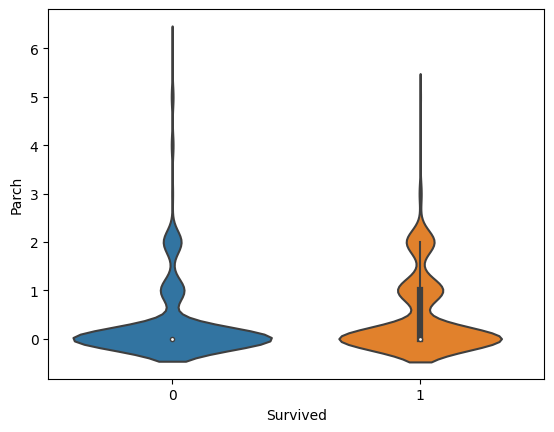

In [29]:
# Feautre 6: --> Parch
df.groupby(df['Parch'] > 0)['Survived'].mean()
sns.violinplot(data=df, x="Survived", y="Parch")

In [30]:
# Faeutre 7: --> Ticket

df.sort_values('Ticket').Ticket.values[:20]

array(['110152', '110152', '110152', '110413', '110413', '110413',
       '110465', '110465', '110564', '110813', '111240', '111320',
       '111361', '111361', '111369', '111426', '111427', '111428',
       '112050', '112052'], dtype=object)

<Axes: xlabel='Survived', ylabel='Fare'>

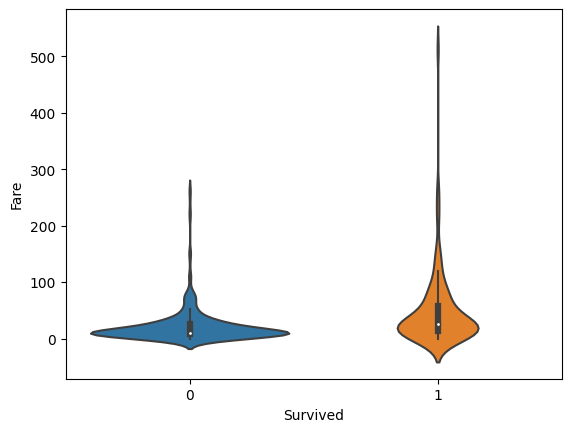

In [31]:
# Featre 8: --> Fare
sns.violinplot(data=df, x="Survived", y="Fare")

In [32]:
Fare_mean = df['Fare'].mean()
df.groupby(df['Fare'] > Fare_mean).Survived.mean()


Fare
False    0.317647
True     0.597156
Name: Survived, dtype: float64

In [33]:
# Feature 8: --> Cabin
df['HasCabin'] = df['Cabin'].notna().astype(int)
print(df.groupby('HasCabin')['Survived'].mean())
df['HasCabin']

HasCabin
0    0.299854
1    0.666667
Name: Survived, dtype: float64


0      0
1      1
2      0
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: HasCabin, Length: 891, dtype: int64

In [34]:
#  Feautre 9: --> Embarked [S, C,Q]
df.groupby('Embarked').Survived.mean()

Embarked
C    0.553571
Q    0.389610
S    0.336957
Name: Survived, dtype: float64

In [35]:
NUMS_FEAUTRES = ['Age', 'Fare', 'SibSp', 'Parch']
CATEGORICAL_FEAUTRES = ['Sex', 'Embarked', 'HasCabin', 'FareOverMean', 'Pclass']
# NON_NUMS_FEAUTRES = ['Cabin', 'TicketPrefix']

def get_ticket_prrefix(ticket):
    if pd.isna(ticket):
        return ticket
    digit = re.search(r'\d', ticket)
    if digit:
        return ticket[:digit.span()[0]].strip()
        
    
def adding_fields(df):
    df['TicketPrefix'] = df['Ticket'].apply(get_ticket_prrefix)
    df['HasCabin'] = df['Cabin'].notna().astype(int)
    df['FareOverMean'] = df['Fare'] > df['Fare'].mean().astype(int)
    df['Pclass'] = df['Pclass'].astype(str)
    return df

def load_df(path):
     return pd.read_csv(path)

def preprocess_nums(df):
    df = df.copy()
    df.loc[df['Age'].isna(), 'Age'] = df['Age'].mean()
    return df


In [36]:
df = load_df('/kaggle/input/titanic/train.csv')
df =adding_fields(df)
df =preprocess_nums(df)
# print(df)

In [37]:
from sklearn.model_selection import train_test_split
df_train, df_test = train_test_split(df, test_size=0.20, random_state=42)

y_train = df_train['Survived'].copy()
y_test = df_test.Survived
# df_train

print(df_train.shape, df_test.shape)

(712, 15) (179, 15)


In [38]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def build_features(df, encoder):
    cat = encoder.transform(df[CATEGORICAL_FEAUTRES])
    cat_df = pd.DataFrame(cat.toarray(), columns=encoder.get_feature_names_out(CATEGORICAL_FEAUTRES), index=df.index)
    num_df = df[NUMS_FEAUTRES].fillna(0)
    return pd.concat([num_df, cat_df], axis=1)

def fit_transformers(df):
    df = preprocess_nums(df)
    df = adding_fields(df)
    encoder = OneHotEncoder(handle_unknown="ignore")
    encoder.fit(df[CATEGORICAL_FEAUTRES])
    features = build_features(df, encoder)
    scaler = StandardScaler()
    scaler.fit(features)
    return scaler, encoder

def compute_features(df, encoder, scaler):
    df = preprocess_nums(df)
    df = adding_fields(df)
    features = build_features(df, encoder)
    scaled = scaler.transform(features)
    return pd.DataFrame(scaled, columns=features.columns, index=df.index)

scaler, encoder = fit_transformers(df_train)

X_train = compute_features(df_train, encoder, scaler)
X_test = compute_features(df_test, encoder, scaler)


In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = LogisticRegression()
model.fit(X_train, y_train)


y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2%}")

Accuracy: 80.45%


In [40]:
sub_df = load_df('/kaggle/input/titanic/test.csv')
sub_x = compute_features(sub_df, encoder, scaler)
y_subs = model.predict(sub_x)
submission = pd.DataFrame({'PassengerId': sub_df['PassengerId'],'Survived': y_subs})
submission.to_csv('submission.csv', index=False)
submission

/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in greater
  return op(a, b)


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1
...,...,...
413,1305,0
414,1306,1
415,1307,0
416,1308,0
